# Subgroup Fairness Analysis

### Objective
Evaluate whether our final XGBoost model performs consistently
across demographic subgroups, including sex, age, and race/ethnicity.

We compare recall, precision, F1, false positive rate,
PR-AUC, and ROC-AUC using the team's selected decision
threshold of 0.055.

This analysis uses the held-out test set.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

## 1. Load Test Predictions

We use the final XGBoost model's predictions on the held-out test set to evaluate performance across demographic groups.

The model uses a threshold of approximately 0.055, selected on the validation set to target 80% recall.

In [3]:
from pathlib import Path

# Find the repository's root folder
ROOT = Path.cwd()

if ROOT.name == "Notebooks":
    ROOT = ROOT.parent

# Load predictions exported from the SHAP notebook
file_path = ROOT / "outputs" / "shap" / "fairness_test_predictions.csv"

fairness_df = pd.read_csv(file_path)

print("Dataset shape:", fairness_df.shape)
display(fairness_df.head())

Dataset shape: (88414, 45)


,Sex,GeneralHealth,PhysicalHealthDays,MentalHealthDays,LastCheckupTime,PhysicalActivities,SleepHours,RemovedTeeth,HadAngina,HadStroke,...,TetanusLast10Tdap,HighRiskLastYear,CovidPos,chronic_count,diabetes_yes,disability_count,n_missing,Actual,Probability,Predicted
0,1.0,2.0,0.0,2.0,0.0,1.0,6.0,2.0,0.0,0.0,...,NaN,1.0,No,1.0,0.0,0.0,2,0,0.057723,1
1,1.0,1.0,0.0,0.0,0.0,1.0,5.0,1.0,0.0,0.0,...,NaN,NaN,NaN,0.0,1.0,0.0,19,0,0.067524,1
2,1.0,2.0,5.0,0.0,1.0,0.0,7.0,0.0,0.0,0.0,...,"Yes, received Tdap",0.0,No,0.0,0.0,0.0,0,0,0.027019,0
3,0.0,3.0,0.0,4.0,0.0,0.0,7.0,NaN,0.0,0.0,...,"No, did not receive any tetanus shot in the pa...",0.0,Yes,2.0,0.0,0.0,1,0,0.016902,0
4,0.0,3.0,0.0,4.0,0.0,1.0,8.0,0.0,0.0,0.0,...,"No, did not receive any tetanus shot in the pa...",1.0,Tested positive using home test without a heal...,1.0,0.0,0.0,0,0,0.003197,0


## 2. Subgroup Fairness Evaluation

We evaluate the XGBoost model across demographic groups using precision, recall, F1, false positive rate, ROC-AUC, and PR-AUC.

All groups use the same prediction threshold, approximately 0.055, selected on the validation set.

In [5]:
def calculate_metrics(group):
    y_true = group["Actual"]
    y_pred = group["Predicted"]
    y_prob = group["Probability"]

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return pd.Series({
        "Count": len(group),
        "Positive Rate": y_true.mean(),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "FPR": fp / (fp + tn) if (fp + tn) > 0 else np.nan,
        "ROC-AUC": roc_auc_score(y_true, y_prob) if y_true.nunique() == 2 else np.nan,
        "PR-AUC": average_precision_score(y_true, y_prob) if y_true.nunique() == 2 else np.nan
    })

In [6]:
sex_results = pd.DataFrame({
    name: calculate_metrics(group)
    for name, group in fairness_df.groupby("Sex")
}).T

display(sex_results.round(4))

,Count,Positive Rate,Precision,Recall,F1,FPR,ROC-AUC,PR-AUC
0.0,46783.0,0.0405,0.1827,0.7182,0.2913,0.1356,0.8813,0.3268
1.0,41631.0,0.0751,0.2245,0.8331,0.3537,0.2337,0.8909,0.4860


### Fairness by Age Group and Race/Ethnicity

We compare model performance across age groups and racial/ethnic categories to identify differences in recall, precision, and false positive rates.

In [7]:
# Fairness by age group
age_results = pd.DataFrame({
    name: calculate_metrics(group)
    for name, group in fairness_df.groupby("AgeCategory", observed=True)
}).T

print("Fairness by Age Group")
display(age_results.round(4))


# Fairness by race/ethnicity
race_results = pd.DataFrame({
    name: calculate_metrics(group)
    for name, group in fairness_df.groupby("RaceEthnicityCategory", observed=True)
}).T

print("Fairness by Race/Ethnicity")
display(race_results.round(4))

Fairness by Age Group


,Count,Positive Rate,Precision,Recall,F1,FPR,ROC-AUC,PR-AUC
18.0,5401.0,0.0043,0.1915,0.3913,0.2571,0.0071,0.7998,0.1920
25.0,4392.0,0.0059,0.1778,0.3077,0.2254,0.0085,0.7377,0.1705
30.0,5130.0,0.0080,0.1685,0.3659,0.2308,0.0145,0.8475,0.2434
35.0,5669.0,0.0093,0.1429,0.3774,0.2073,0.0214,0.8490,0.1820
40.0,6002.0,0.0152,0.1457,0.3187,0.2000,0.0288,0.8443,0.2063
45.0,5645.0,0.0220,0.1709,0.5968,0.2657,0.0650,0.8899,0.3042
50.0,6663.0,0.0345,0.2062,0.6652,0.3148,0.0916,0.8772,0.3989
55.0,7335.0,0.0592,0.2434,0.7604,0.3687,0.1487,0.8798,0.4686
60.0,8727.0,0.0619,0.1999,0.7796,0.3182,0.2058,0.8645,0.4138
65.0,9396.0,0.0809,0.2165,0.7934,0.3402,0.2527,0.8592,0.4719


Fairness by Race/Ethnicity


,Count,Positive Rate,Precision,Recall,F1,FPR,ROC-AUC,PR-AUC
"Black only, Non-Hispanic",6879.0,0.0456,0.1757,0.7707,0.2862,0.1729,0.8794,0.3520
Hispanic,8554.0,0.0400,0.1911,0.6784,0.2982,0.1196,0.8655,0.3693
"Multiracial, Non-Hispanic",1912.0,0.0586,0.2236,0.8304,0.3523,0.1794,0.9149,0.5462
"Other race only, Non-Hispanic",4453.0,0.0406,0.2024,0.8508,0.3270,0.1421,0.9287,0.4844
"White only, Non-Hispanic",63912.0,0.0608,0.2114,0.7960,0.3340,0.1923,0.8899,0.4354


## 3. Fairness Visualizations

We compare recall and false positive rates across demographic groups using the same model threshold.

Recall measures the proportion of participants who reported a heart attack history that the model correctly identifies.

False positive rate measures the proportion of participants who reported no heart attack history that the model incorrectly predicts as positive.

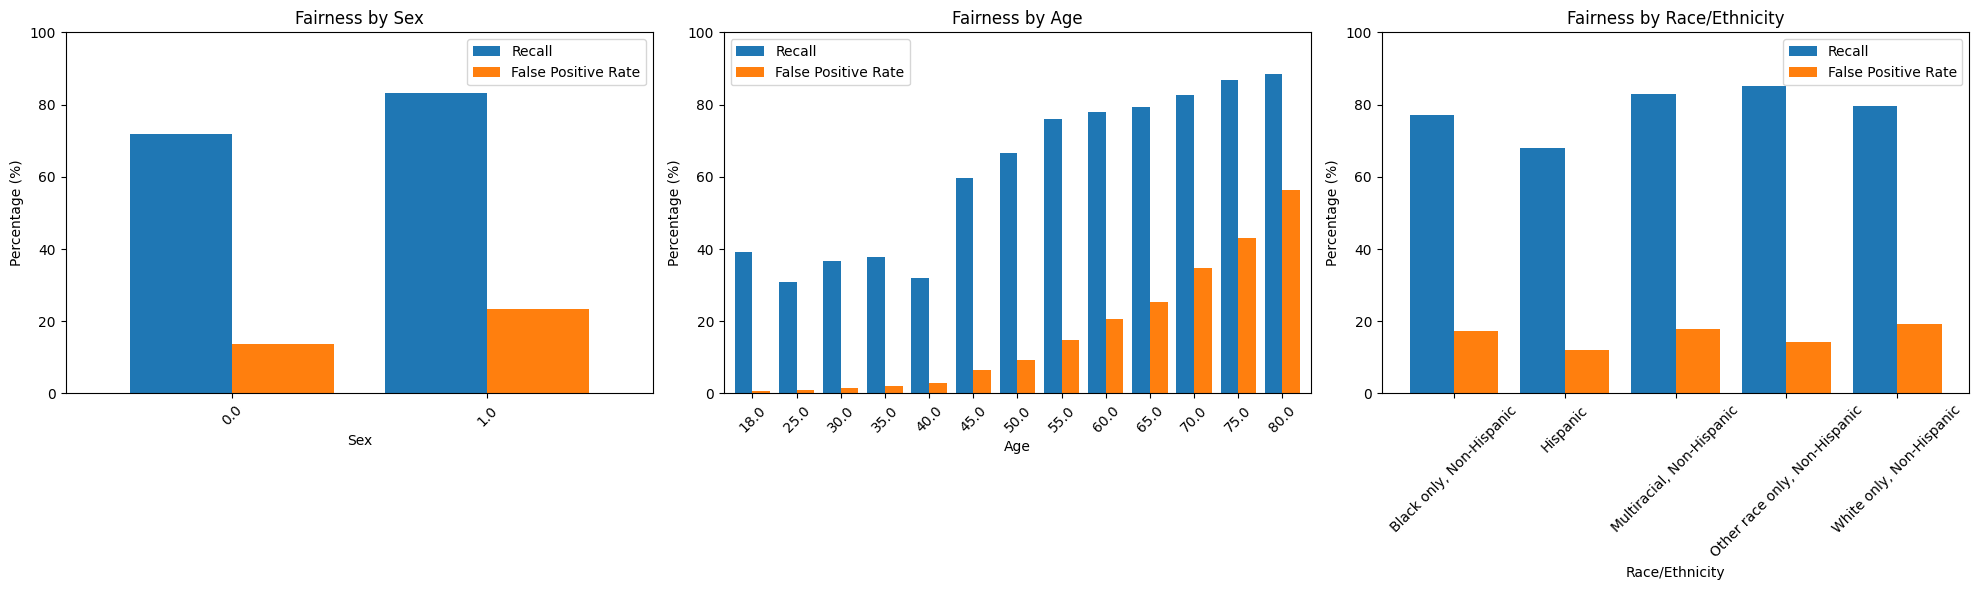

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

groups = [
    ("Sex", sex_results),
    ("Age", age_results),
    ("Race/Ethnicity", race_results)
]

for ax, (name, results) in zip(axes, groups):
    plot_data = results[["Recall", "FPR"]].copy() * 100

    plot_data.plot(
        kind="bar",
        ax=ax,
        width=0.8
    )

    ax.set_title(f"Fairness by {name}")
    ax.set_ylabel("Percentage (%)")
    ax.set_xlabel(name)
    ax.set_ylim(0, 100)
    ax.legend(["Recall", "False Positive Rate"])
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

## 4. Key Findings

We evaluated XGBoost fairness across sex, age, and race/ethnicity using 88,414 test samples and a threshold of approximately 0.055, selected to target 80% recall on validation data.

- **Sex:** Recall differed by 11.49 percentage points (71.82% vs. 83.31%), with false positive rates of 13.56% and 23.37%.
- **Age:** Recall generally increased with age, from 30.77% (age 25) to 88.35% (age 80). However, the false positive rate also increased, reaching 56.30% for age 80.
- **Race/Ethnicity:** Hispanic participants had the lowest recall (67.84%), compared with 85.08% for the Other race only, Non-Hispanic group, a 17.24 percentage-point gap.

## 5. Limitations

- **Self-reported data:** Heart attack history was based on survey responses rather than medically verified diagnoses.
- **Class imbalance:** Only 5.68% of participants reported a heart attack, meaning the dataset contains significantly more negative than positive cases. This can make it harder for the model to identify positive cases accurately.
- **Subgroup differences:** Demographic groups have different sample sizes and heart attack prevalence rates. Smaller groups may produce less reliable estimates, while differences in prevalence can affect metrics such as precision and PR-AUC.
- **Model versions:** Different XGBoost versions may produce slightly different predictions, thresholds, and results due to variations in model training.
- **Fairness:** Performance gaps across demographic groups suggest potential fairness concerns, but these differences alone do not prove discrimination. Further investigation is needed to understand their causes.

## 6. Conclusion

XGBoost achieved a test ROC-AUC of 0.8907, PR-AUC of 0.4318, and recall of 78.97%. However, performance varied across demographic groups, particularly age. Further evaluation and potential fairness mitigation are recommended before clinical use.